In [2]:
import pandas as pd


In [3]:
import pandas as pd

df = pd.read_csv("data/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv")

df.info()

head = df.head(2)
head

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
 8   segment          64000 non-null  object 
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 5.9+ MB


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
 8   segment          64000 non-null  object 
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 5.9+ MB


In [5]:
df.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [6]:

# STAGE 1 — DATA AUDIT


binary_cols = ["mens", "womens", "newbie", "visit", "conversion"]

print("=== DATASET SHAPE ===")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print("\n=== GRAIN ===")
print("Expected grain: one row = one customer in the experiment")

print("\n=== DUPLICATE ROWS ===")
print(f"Duplicate rows: {df.duplicated().sum():,}")

print("\n=== MISSING VALUES ===")
missing = df.isna().sum()
print(missing[missing > 0] if missing.any() else "No missing values")

print("\n=== DATA TYPES ===")
print(df.dtypes)

print("\n=== BINARY COLUMN CHECK ===")
for col in binary_cols:
    values = sorted(df[col].dropna().unique().tolist())
    print(f"{col}: {values}")

=== DATASET SHAPE ===
Rows: 64,000
Columns: 12

=== GRAIN ===
Expected grain: one row = one customer in the experiment

=== DUPLICATE ROWS ===
Duplicate rows: 6,562

=== MISSING VALUES ===
No missing values

=== DATA TYPES ===
recency              int64
history_segment     object
history            float64
mens                 int64
womens               int64
zip_code            object
newbie               int64
channel             object
segment             object
visit                int64
conversion           int64
spend              float64
dtype: object

=== BINARY COLUMN CHECK ===
mens: [0, 1]
womens: [0, 1]
newbie: [0, 1]
visit: [0, 1]
conversion: [0, 1]


In [7]:
# STAGE 1 — DATA AUDIT
duplicate_mask = df.duplicated(keep=False)
duplicate_rows = df.loc[duplicate_mask]

print("=== DUPLICATE ROW INVESTIGATION ===")
print(f"Rows involved in duplicate groups:{len(duplicate_rows):,}")

print("\n=== UNIQUE ROWS ===")
print(f"Unique complete rows:{df.drop_duplicates().shape[0]:,}")

print("\n=== DUPLICATE FREQUENCY ===")
duplicate_frequency = (
    duplicate_rows
    .value_counts()
    .rename("row_count")
    .reset_index()
    .sort_values("row_count", ascending=False)
)

print(duplicate_frequency.head(10).to_string(index=False))

print("\n=== DUPLICATE GROUP SUMMARY ===")
print(f"Number of duplicated row patterns:{len(duplicate_frequency):,}")
print(f"Maximum repetition of one identical row:{duplicate_frequency['row_count'].max()}")

=== DUPLICATE ROW INVESTIGATION ===
Rows involved in duplicate groups:7,634

=== UNIQUE ROWS ===
Unique complete rows:57,438

=== DUPLICATE FREQUENCY ===
 recency history_segment  history  mens  womens  zip_code  newbie channel       segment  visit  conversion  spend  row_count
      10    1) $0 - $100    29.99     0       1 Surburban       1   Phone   Mens E-Mail      0           0    0.0         31
      10    1) $0 - $100    29.99     1       0 Surburban       0     Web Womens E-Mail      0           0    0.0         27
      10    1) $0 - $100    29.99     0       1     Urban       1   Phone Womens E-Mail      0           0    0.0         27
      10    1) $0 - $100    29.99     1       0 Surburban       0   Phone     No E-Mail      0           0    0.0         27
      10    1) $0 - $100    29.99     1       0 Surburban       1   Phone     No E-Mail      0           0    0.0         26
      10    1) $0 - $100    29.99     1       0 Surburban       1     Web     No E-Mail      0  

In [8]:
# Categorical values and experimental group counts

categorical_cols = [
    "segment",
    "channel",
    "zip_code",
    "history_segment"
]

for col in categorical_cols:
    print(f"\n=== {col.upper()} ===")
    print(f"Unique categories: {df[col].nunique(dropna=False)}")
    print(df[col].value_counts(dropna=False).to_string())

print("\n=== EXPERIMENTAL GROUP RECONCILIATION ===")
segment_counts = df["segment"].value_counts(dropna=False)

print(segment_counts)

print(f"\nTotal across experimental groups: {segment_counts.sum():,}")
print(f"Original dataframe rows: {len(df):,}")
print(
    "Reconciles:",
    segment_counts.sum() == len(df)
)


=== SEGMENT ===
Unique categories: 3
segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306

=== CHANNEL ===
Unique categories: 3
channel
Web             28217
Phone           28021
Multichannel     7762

=== ZIP_CODE ===
Unique categories: 3
zip_code
Surburban    28776
Urban        25661
Rural         9563

=== HISTORY_SEGMENT ===
Unique categories: 7
history_segment
1) $0 - $100        22970
2) $100 - $200      14254
3) $200 - $350      12289
4) $350 - $500       6409
5) $500 - $750       4911
6) $750 - $1,000     1859
7) $1,000 +          1308

=== EXPERIMENTAL GROUP RECONCILIATION ===
segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

Total across experimental groups: 64,000
Original dataframe rows: 64,000
Reconciles: True


In [9]:
 # Logical consistency and impossible-value checks
print("=== NEGATIVE VALUES ===")
print(f"Negative recency: {((df['recency'] < 0)).sum():,}")
print(f"Negative history: {((df['history'] < 0)).sum():,}")
print(f"Negative spend: {((df['spend'] < 0)).sum():,}")

print("\n=== VISIT / CONVERSION CONSISTENCY ===")
conversion_without_visit = (df["conversion"] > df["visit"]).sum()
print(f"Rows where conversion > visit: {conversion_without_visit:,}")

print("\n=== CONVERSION / SPEND CONSISTENCY ===")
no_conversion_positive_spend = (
    (df["conversion"] == 0 ) & (df["spend"] > 0)
).sum()

conversion_zero_spend = (
    (df["conversion"] == 1) & (df["spend"] == 0)
).sum()

print(f"Conversion = 0 but spend > 0: {no_conversion_positive_spend:,}")
print(f"Conversion = 1 but spend = 0: {conversion_zero_spend:,}")

print("\n=== KEY NUMERIC SUMMARIES ===")
print(df[["recency", "history", "spend"]].describe().T)

=== NEGATIVE VALUES ===
Negative recency: 0
Negative history: 0
Negative spend: 0

=== VISIT / CONVERSION CONSISTENCY ===
Rows where conversion > visit: 0

=== CONVERSION / SPEND CONSISTENCY ===
Conversion = 0 but spend > 0: 0
Conversion = 1 but spend = 0: 0

=== KEY NUMERIC SUMMARIES ===
           count        mean         std    min    25%     50%       75%  \
recency  64000.0    5.763734    3.507592   1.00   2.00    6.00    9.0000   
history  64000.0  242.085656  256.158608  29.99  64.66  158.11  325.6575   
spend    64000.0    1.050908   15.036448   0.00   0.00    0.00    0.0000   

             max  
recency    12.00  
history  3345.93  
spend     499.00  


### Observation — Distribution of Customer Spend

The `spend` variable is highly **zero-heavy and right-skewed** in this dataset.

The median spend is 0, while the mean is approximately 1.05 and the maximum is 499. This indicates that most customers have no observed spend, while a relatively small number of customers have substantially larger spend values, creating a long right tail.

`history` is also right-skewed: its mean (approximately 242) is higher than its median (approximately 158), with a maximum of approximately 3,346.

These distributions are important because extreme but legitimate customers can strongly influence average spend. Therefore, unusual observations will be investigated rather than automatically removed.

For the later treatment-effect analysis of spend, we will retain valid observations and use an approach that is appropriate for a highly skewed outcome, including bootstrap confidence intervals for uncertainty.

In [10]:
# Numeric tail and outlier investigation

numeric_cols = ["recency", "history", "spend"]

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    upper_fence = q3 + 1.5 * iqr

    print(f"\n=== {col.upper()} ===")
    print(f"Q1: {q1:.2f}")
    print(f"Q3: {q3:.2f}")
    print(f"IQR: {iqr:.2f}")
    print(f"Upper IQR Fence: {upper_fence:.2f}")
    print(f"Maximum: {df[col].max():.2f}")
    print(f"Rows above upper fence: {(df[col] > upper_fence).sum():,}")

print("\n=== EXTREME SPEND VALUES ===")
print(
    df[["recency", "history", "spend", "segment"]]
    .sort_values("spend", ascending=False)
    .head(10)
    .to_string(index=False)
)


=== RECENCY ===
Q1: 2.00
Q3: 9.00
IQR: 7.00
Upper IQR Fence: 19.50
Maximum: 12.00
Rows above upper fence: 0

=== HISTORY ===
Q1: 64.66
Q3: 325.66
IQR: 261.00
Upper IQR Fence: 717.15
Maximum: 3345.93
Rows above upper fence: 3,593

=== SPEND ===
Q1: 0.00
Q3: 0.00
IQR: 0.00
Upper IQR Fence: 0.00
Maximum: 499.00
Rows above upper fence: 578

=== EXTREME SPEND VALUES ===
 recency  history  spend       segment
       6   625.48  499.0   Mens E-Mail
       1  1096.52  499.0     No E-Mail
       4    29.99  499.0 Womens E-Mail
       2    50.39  499.0   Mens E-Mail
       1  1515.82  499.0 Womens E-Mail
       1   365.79  499.0   Mens E-Mail
       4  1434.90  499.0 Womens E-Mail
       2    39.31  499.0 Womens E-Mail
       3  1020.83  499.0   Mens E-Mail
      12    29.99  499.0   Mens E-Mail


In [11]:
# Investigate the upper spend boundary


print("=== MAXIMUM SPEND FREQUENCY ===")

max_spend = df["spend"].max()
max_spend_count = (df["spend"] == max_spend).sum()

print(f"Maximum spend value: {max_spend:.2f}")
print(f"Rows at maximum: {max_spend_count:,}")

print("\n=== TOP UNIQUE SPEND VALUES ===")

top_spend_values = (
    df["spend"]
    .value_counts()
    .sort_index(ascending=False)
    .head(15)
)

print(top_spend_values.to_string())

print("\n=== SPEND QUANTILES ===")
spend_quantiles = df["spend"].quantile(
    [0.90, 0.95, 0.99, 0.995, 0.999]
)

print(spend_quantiles.to_string())

=== MAXIMUM SPEND FREQUENCY ===
Maximum spend value: 499.00
Rows at maximum: 12

=== TOP UNIQUE SPEND VALUES ===
spend
499.00    12
482.31     1
462.78     1
444.92     1
444.33     1
421.76     1
421.17     1
414.08     1
397.32     1
397.29     1
395.24     1
393.43     1
385.28     1
384.83     1
382.78     1

=== SPEND QUANTILES ===
0.900      0.00000
0.950      0.00000
0.990      0.00000
0.995     68.37135
0.999    243.66049


In [12]:
# Validate history_segment against history

history_segment_summary = (
    df.groupby("history_segment", observed=True)["history"]
    .agg(
        count="size",
        min_history="min",
        max_history="max",
        median_history="median"
    )
    .reset_index()
)

print("=== HISTORY SEGMENT → HISTORY SUMMARY ===")
print(
    history_segment_summary
    .to_string(index=False)
)

=== HISTORY SEGMENT → HISTORY SUMMARY ===
 history_segment  count  min_history  max_history  median_history
    1) $0 - $100  22970        29.99        99.99          44.545
  2) $100 - $200  14254       100.00       199.98         144.765
  3) $200 - $350  12289       200.00       349.96         262.490
  4) $350 - $500   6409       350.01       499.95         414.560
  5) $500 - $750   4911       500.00       749.79         595.380
6) $750 - $1,000   1859       750.01       999.75         841.760
     7) $1,000 +   1308      1000.15      3345.93        1214.500


In [13]:
import numpy as np

control_label = "No E-Mail"
treatment_labels = ["Mens E-Mail", "Womens E-Mail"]

continuous_cols = ["recency", "history"]
binary_cols = ["mens", "womens", "newbie"]


def continuous_smd(treatment, control):
    """Standardized mean difference for a continuous variable."""
    treatment_mean = treatment.mean()
    control_mean = control.mean()

    treatment_var = treatment.var(ddof=1)
    control_var = control.var(ddof=1)

    pooled_sd = np.sqrt((treatment_var + control_var) / 2)

    return (treatment_mean - control_mean) / pooled_sd


def binary_smd(treatment, control):
    """Standardized mean difference for a binary variable."""
    treatment_prop = treatment.mean()
    control_prop = control.mean()

    pooled_variance = (
        treatment_prop * (1 - treatment_prop)
        + control_prop * (1 - control_prop)
    ) / 2

    pooled_sd = np.sqrt(pooled_variance)

    return (treatment_prop - control_prop) / pooled_sd


rows = []

for treatment_label in treatment_labels:
    treatment_df = df[df["segment"] == treatment_label]
    control_df = df[df["segment"] == control_label]

    for col in continuous_cols:
        rows.append({
            "comparison": f"{treatment_label} vs {control_label}",
            "variable": col,
            "treatment_value": treatment_df[col].mean(),
            "control_value": control_df[col].mean(),
            "smd": continuous_smd(
                treatment_df[col],
                control_df[col]
            )
        })

    for col in binary_cols:
        rows.append({
            "comparison": f"{treatment_label} vs {control_label}",
            "variable": col,
            "treatment_value": treatment_df[col].mean(),
            "control_value": control_df[col].mean(),
            "smd": binary_smd(
                treatment_df[col],
                control_df[col]
            )
        })

balance_numeric = pd.DataFrame(rows)

balance_numeric["abs_smd"] = balance_numeric["smd"].abs()

print("=== PRE-TREATMENT BALANCE: NUMERIC + BINARY ===")

print(
    balance_numeric[
        [
            "comparison",
            "variable",
            "treatment_value",
            "control_value",
            "smd",
            "abs_smd"
        ]
    ].to_string(index=False)
)

print("\n=== LARGEST ABSOLUTE SMD BY COMPARISON ===")

print(
    balance_numeric
    .groupby("comparison")["abs_smd"]
    .max()
    .to_string()
)

=== PRE-TREATMENT BALANCE: NUMERIC + BINARY ===
                comparison variable  treatment_value  control_value       smd  abs_smd
  Mens E-Mail vs No E-Mail  recency         5.773642       5.749695  0.006832 0.006832
  Mens E-Mail vs No E-Mail  history       242.835931     240.882653  0.007613 0.007613
  Mens E-Mail vs No E-Mail     mens         0.550946       0.553224 -0.004582 0.004582
  Mens E-Mail vs No E-Mail   womens         0.551415       0.547639  0.007589 0.007589
  Mens E-Mail vs No E-Mail   newbie         0.501525       0.501971 -0.000892 0.000892
Womens E-Mail vs No E-Mail  recency         5.767850       5.749695  0.005180 0.005180
Womens E-Mail vs No E-Mail  history       242.536633     240.882653  0.006511 0.006511
Womens E-Mail vs No E-Mail     mens         0.548932       0.553224 -0.008631 0.008631
Womens E-Mail vs No E-Mail   womens         0.550101       0.547639  0.004946 0.004946
Womens E-Mail vs No E-Mail   newbie         0.503250       0.501971  0.002557 0.00

In [14]:
# Categorical covariate balance

import pandas as pd


def cramers_v(table):
    """
    Calculate Cramer's V for a contingency table.
    """
    observed = table.to_numpy()

    row_totals = observed.sum(axis=1, keepdims=True)
    col_totals = observed.sum(axis=0, keepdims=True)
    total = observed.sum()

    expected = row_totals @ col_totals / total

    chi2 = ((observed - expected) ** 2 / expected).sum()

    r, k = observed.shape
    phi2 = chi2 / total

    phi2_corrected = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (total - 1)
    )

    r_corrected = r - ((r - 1) ** 2) / (total - 1)
    k_corrected = k - ((k - 1) ** 2) / (total - 1)

    return np.sqrt(
        phi2_corrected /
        min(k_corrected - 1, r_corrected - 1)
    )


categorical_balance_cols = ["channel", "zip_code"]

for col in categorical_balance_cols:
    print(f"\n=== {col.upper()} BALANCE ===")

    counts = pd.crosstab(
        df["segment"],
        df[col]
    )

    proportions = pd.crosstab(
        df["segment"],
        df[col],
        normalize="index"
    ) * 100

    print("\nCounts:")
    print(counts.to_string())

    print("\nRow percentages:")
    print(proportions.round(2).to_string())

    print(f"\nCramer's V: {cramers_v(counts):.6f}")


=== CHANNEL BALANCE ===

Counts:
channel        Multichannel  Phone   Web
segment                                 
Mens E-Mail            2577   9240  9490
No E-Mail              2606   9327  9373
Womens E-Mail          2579   9454  9354

Row percentages:
channel        Multichannel  Phone    Web
segment                                  
Mens E-Mail           12.09  43.37  44.54
No E-Mail             12.23  43.78  43.99
Womens E-Mail         12.06  44.20  43.74

Cramer's V: 0.000000

=== ZIP_CODE BALANCE ===

Counts:
zip_code       Rural  Surburban  Urban
segment                               
Mens E-Mail     3243       9501   8563
No E-Mail       3139       9625   8542
Womens E-Mail   3181       9650   8556

Row percentages:
zip_code       Rural  Surburban  Urban
segment                               
Mens E-Mail    15.22      44.59  40.19
No E-Mail      14.73      45.18  40.09
Womens E-Mail  14.87      45.12  40.01

Cramer's V: 0.000000


### SQL ANALYTICS LAYER

In [15]:


#Create local DuckDB analytical database

from pathlib import Path
import duckdb

db_path = Path("../data/email_experiment.duckdb")
db_path.parent.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(db_path))

con.register("df_source", df)

con.execute("""
    CREATE OR REPLACE TABLE customer_experiment AS
    SELECT *
    FROM df_source
""")

row_count = con.execute("""
    SELECT COUNT(*)
    FROM customer_experiment
""").fetchone()[0]

print(f"DuckDB database: {db_path}")
print(f"Table: customer_experiment")
print(f"Rows loaded: {row_count:,}")
print(f"Expected rows: {len(df):,}")
print(f"Row-count reconciliation: {row_count == len(df)}")

DuckDB database: ../data/email_experiment.duckdb
Table: customer_experiment
Rows loaded: 64,000
Expected rows: 64,000
Row-count reconciliation: True


In [16]:
import os
os.listdir()

['.DS_Store',
 'GLOSSARY.md',
 'retail_email_incrementality_project',
 'retail_email_incrementality_project.zip',
 '.ipynb_checkpoints',
 'Interview text.ipynb',
 '.vscode',
 'data',
 'notebooks',
 'analysis.ipynb',
 'retail_email_decision_workbook.xlsx',
 'DECISIONS.md',
 'sql']

In [17]:
os.listdir("data")

['email_experiment.duckdb.wal',
 'Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv',
 'email_experiment.duckdb']

In [18]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nDuckDB path:")
db_path = Path("../data/email_experiment.duckdb")
print(db_path.resolve())

print("\nDoes it exist?")
print(db_path.exists())

Current working directory:
/Users/waheed/Desktop/Project3

DuckDB path:
/Users/waheed/Desktop/data/email_experiment.duckdb

Does it exist?
True


In [19]:
from pathlib import Path
import duckdb

db_path = Path("data/email_experiment.duckdb")

print("Database path:")
print(db_path.resolve())

print("\nDoes it exist?")
print(db_path.exists())

con = duckdb.connect(str(db_path))

print("\nRows in customer_experiment:")
print(con.execute("SELECT COUNT(*) FROM customer_experiment").fetchone()[0])

Database path:
/Users/waheed/Desktop/Project3/data/email_experiment.duckdb

Does it exist?
True

Rows in customer_experiment:
64000


In [20]:
# ============================================================
# STAGE 2A — ARM-LEVEL CAMPAIGN METRICS
# Grain: one row per experimental arm
# ============================================================

con.execute("""
CREATE OR REPLACE TABLE arm_metrics AS

SELECT
    segment,

    COUNT(*) AS customers,

    SUM(visit) AS visits,
    SUM(conversion) AS conversions,
    SUM(spend) AS total_spend,

    AVG(visit) AS visit_rate,
    AVG(conversion) AS conversion_rate,
    AVG(spend) AS avg_spend_per_customer

FROM customer_experiment

GROUP BY segment

ORDER BY
    CASE segment
        WHEN 'Mens E-Mail' THEN 1
        WHEN 'Womens E-Mail' THEN 2
        WHEN 'No E-Mail' THEN 3
    END
""")

# Reconcile the analytical table back to the source population.

reconciliation = con.execute("""
SELECT
    SUM(customers) AS total_customers_across_arms,
    (SELECT COUNT(*) FROM customer_experiment) AS source_customers,
    SUM(customers) = (SELECT COUNT(*) FROM customer_experiment)
        AS row_count_reconciles
FROM arm_metrics
""").df()

print("Reconciliation:")
display(reconciliation)

# Display the analytical table.

arm_metrics_df = con.execute("""
SELECT
    segment,
    customers,
    visits,
    ROUND(visit_rate * 100, 3) AS visit_rate_pct,
    conversions,
    ROUND(conversion_rate * 100, 3) AS conversion_rate_pct,
    ROUND(total_spend, 2) AS total_spend,
    ROUND(avg_spend_per_customer, 4) AS avg_spend_per_customer
FROM arm_metrics
""").df()

display(arm_metrics_df)

Reconciliation:


,total_customers_across_arms,source_customers,row_count_reconciles
0,64000.0,64000,True


,segment,customers,visits,visit_rate_pct,conversions,conversion_rate_pct,total_spend,avg_spend_per_customer
0,Mens E-Mail,21307,3894.0,18.276,267.0,1.253,30311.69,1.4226
1,Womens E-Mail,21387,3238.0,15.140,189.0,0.884,23038.11,1.0772
2,No E-Mail,21306,2262.0,10.617,122.0,0.573,13908.33,0.6528


In [21]:
# ============================================================
# STAGE 2B — UPLIFT VS NO EMAIL
# Grain: one row per treatment arm
# ============================================================

uplift_df = con.execute("""
WITH control AS (
    SELECT
        visit_rate AS control_visit_rate,
        conversion_rate AS control_conversion_rate,
        avg_spend_per_customer AS control_avg_spend
    FROM arm_metrics
    WHERE segment = 'No E-Mail'
),

treatments AS (
    SELECT
        segment,
        customers,
        visit_rate,
        conversion_rate,
        avg_spend_per_customer
    FROM arm_metrics
    WHERE segment IN ('Mens E-Mail', 'Womens E-Mail')
)

SELECT
    t.segment,
    t.customers,

    ROUND(t.visit_rate * 100, 3) AS visit_rate_pct,
    ROUND(c.control_visit_rate * 100, 3) AS control_visit_rate_pct,
    ROUND((t.visit_rate - c.control_visit_rate) * 100, 3)
        AS visit_uplift_pp,

    ROUND(t.conversion_rate * 100, 3) AS conversion_rate_pct,
    ROUND(c.control_conversion_rate * 100, 3)
        AS control_conversion_rate_pct,
    ROUND((t.conversion_rate - c.control_conversion_rate) * 100, 3)
        AS conversion_uplift_pp,

    ROUND(t.avg_spend_per_customer, 4) AS avg_spend_per_customer,
    ROUND(c.control_avg_spend, 4) AS control_avg_spend_per_customer,
    ROUND(t.avg_spend_per_customer - c.control_avg_spend, 4)
        AS spend_uplift_per_customer,

    ROUND(
        100 * (t.avg_spend_per_customer - c.control_avg_spend)
        / NULLIF(c.control_avg_spend, 0),
        2
    ) AS spend_relative_uplift_pct

FROM treatments t
CROSS JOIN control c

ORDER BY
    CASE t.segment
        WHEN 'Mens E-Mail' THEN 1
        WHEN 'Womens E-Mail' THEN 2
    END
""").df()

display(uplift_df)

,segment,customers,visit_rate_pct,control_visit_rate_pct,visit_uplift_pp,conversion_rate_pct,control_conversion_rate_pct,conversion_uplift_pp,avg_spend_per_customer,control_avg_spend_per_customer,spend_uplift_per_customer,spend_relative_uplift_pct
0,Mens E-Mail,21307,18.276,10.617,7.659,1.253,0.573,0.681,1.4226,0.6528,0.7698,117.93
1,Womens E-Mail,21387,15.140,10.617,4.523,0.884,0.573,0.311,1.0772,0.6528,0.4244,65.02


In [22]:
# ============================================================
# STAGE 2C — HISTORY SEGMENT PERFORMANCE
# Grain: one row per experimental arm × history segment
# ============================================================

history_segment_df = con.execute("""
SELECT
    segment,
    history_segment,

    COUNT(*) AS customers,

    SUM(visit) AS visits,
    SUM(conversion) AS conversions,
    ROUND(SUM(spend), 2) AS total_spend,

    ROUND(AVG(visit) * 100, 3) AS visit_rate_pct,
    ROUND(AVG(conversion) * 100, 3) AS conversion_rate_pct,
    ROUND(AVG(spend), 4) AS avg_spend_per_customer

FROM customer_experiment

GROUP BY
    segment,
    history_segment

ORDER BY
    CASE segment
        WHEN 'Mens E-Mail' THEN 1
        WHEN 'Womens E-Mail' THEN 2
        WHEN 'No E-Mail' THEN 3
    END,
    history_segment
""").df()

display(history_segment_df)

,segment,history_segment,customers,visits,conversions,total_spend,visit_rate_pct,conversion_rate_pct,avg_spend_per_customer
0,Mens E-Mail,1) $0 - $100,7724,1185.0,71.0,8150.18,15.342,0.919,1.0552
1,Mens E-Mail,2) $100 - $200,4691,751.0,42.0,5287.43,16.009,0.895,1.1271
2,Mens E-Mail,3) $200 - $350,4090,862.0,63.0,6010.10,21.076,1.540,1.4695
3,Mens E-Mail,4) $350 - $500,2097,502.0,42.0,5408.60,23.939,2.003,2.5792
4,Mens E-Mail,5) $500 - $750,1597,333.0,22.0,2622.06,20.852,1.378,1.6419
5,Mens E-Mail,"6) $750 - $1,000",644,139.0,16.0,1213.09,21.584,2.484,1.8837
6,Mens E-Mail,"7) $1,000 +",464,122.0,11.0,1620.23,26.293,2.371,3.4919
7,Womens E-Mail,1) $0 - $100,7634,1005.0,61.0,8723.47,13.165,0.799,1.1427
8,Womens E-Mail,2) $100 - $200,4727,631.0,37.0,4165.85,13.349,0.783,0.8813
9,Womens E-Mail,3) $200 - $350,4155,675.0,26.0,2533.47,16.245,0.626,0.6097


In [23]:
# ============================================================
# STAGE 2 — SQL PIPELINE VALIDATION
# Cell 11: Verify history_segment values across Python and SQL
# ============================================================

pandas_history_segments = sorted(
    df["history_segment"].dropna().unique().tolist()
)

duckdb_history_segments = sorted(
    con.execute("""
        SELECT DISTINCT history_segment
        FROM customer_experiment
        ORDER BY history_segment
    """).df()["history_segment"].tolist()
)

print("=== PANDAS VALUES ===")
for value in pandas_history_segments:
    print(repr(value))

print("\n=== DUCKDB VALUES ===")
for value in duckdb_history_segments:
    print(repr(value))

print("\n=== VALUES PRESENT IN PANDAS BUT NOT DUCKDB ===")
print(
    sorted(
        set(pandas_history_segments) - set(duckdb_history_segments)
    )
)

print("\n=== VALUES PRESENT IN DUCKDB BUT NOT PANDAS ===")
print(
    sorted(
        set(duckdb_history_segments) - set(pandas_history_segments)
    )
)

=== PANDAS VALUES ===
'1) $0 - $100'
'2) $100 - $200'
'3) $200 - $350'
'4) $350 - $500'
'5) $500 - $750'
'6) $750 - $1,000'
'7) $1,000 +'

=== DUCKDB VALUES ===
'1) $0 - $100'
'2) $100 - $200'
'3) $200 - $350'
'4) $350 - $500'
'5) $500 - $750'
'6) $750 - $1,000'
'7) $1,000 +'

=== VALUES PRESENT IN PANDAS BUT NOT DUCKDB ===
[]

=== VALUES PRESENT IN DUCKDB BUT NOT PANDAS ===
[]


In [24]:

# CONVERSION INFERENCE
# One row in the output = one treatment-vs-control comparison


from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)

CONTROL = "No E-Mail"
TREATMENTS = ["Mens E-Mail", "Womens E-Mail"]

results = []

for treatment in TREATMENTS:
    treatment_data = df[df["segment"] == treatment]["conversion"]
    control_data = df[df["segment"] == CONTROL]["conversion"]

    treatment_conversions = treatment_data.sum()
    control_conversions = control_data.sum()

    n_treatment = treatment_data.size
    n_control = control_data.size

    treatment_rate = treatment_data.mean()
    control_rate = control_data.mean()

    absolute_lift = treatment_rate - control_rate

    relative_lift = (
        absolute_lift / control_rate
        if control_rate != 0
        else np.nan
    )

    ci_low, ci_high = confint_proportions_2indep(
        count1=treatment_conversions,
        nobs1=n_treatment,
        count2=control_conversions,
        nobs2=n_control,
        compare="diff",
        method="newcomb",
        alpha=0.05
    )

    z_stat, p_value = proportions_ztest(
        count=[treatment_conversions, control_conversions],
        nobs=[n_treatment, n_control],
        value=0,
        alternative="two-sided"
    )

    results.append({
        "treatment": treatment,
        "treatment_n": n_treatment,
        "control_n": n_control,
        "treatment_conversions": treatment_conversions,
        "control_conversions": control_conversions,
        "treatment_rate": treatment_rate,
        "control_rate": control_rate,
        "absolute_lift": absolute_lift,
        "relative_lift": relative_lift,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "z_stat": z_stat,
        "p_value_raw": p_value
    })

conversion_results = pd.DataFrame(results)

display(
    conversion_results.assign(
        treatment_rate_pct=lambda x: x["treatment_rate"] * 100,
        control_rate_pct=lambda x: x["control_rate"] * 100,
        absolute_lift_pp=lambda x: x["absolute_lift"] * 100,
        relative_lift_pct=lambda x: x["relative_lift"] * 100,
        ci_low_pp=lambda x: x["ci_low"] * 100,
        ci_high_pp=lambda x: x["ci_high"] * 100
    )[
        [
            "treatment",
            "treatment_n",
            "control_n",
            "treatment_conversions",
            "control_conversions",
            "treatment_rate_pct",
            "control_rate_pct",
            "absolute_lift_pp",
            "relative_lift_pct",
            "ci_low_pp",
            "ci_high_pp",
            "z_stat",
            "p_value_raw"
        ]
    ].round(4)
)

,treatment,treatment_n,control_n,treatment_conversions,control_conversions,treatment_rate_pct,control_rate_pct,absolute_lift_pp,relative_lift_pct,ci_low_pp,ci_high_pp,z_stat,p_value_raw
0,Mens E-Mail,21307,21306,267,122,1.2531,0.5726,0.6805,118.8422,0.5014,0.8641,7.3851,0.0000
1,Womens E-Mail,21387,21306,189,122,0.8837,0.5726,0.3111,54.3313,0.1502,0.4745,3.7796,0.0002


In [25]:
# CONVERSION INFERENCE
# One row in the output = one treatment-vs-control comparison

from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)

CONTROL = "No E-Mail"
TREATMENTS = ["Mens E-Mail", "Womens E-Mail"]

results = []

for treatment in TREATMENTS:
    treatment_data = df[df["segment"] == treatment]["conversion"]
    control_data = df[df["segment"] == CONTROL]["conversion"]

    treatment_conversions = treatment_data.sum()
    control_conversions = control_data.sum()

    n_treatment = treatment_data.size
    n_control = control_data.size

    treatment_rate = treatment_data.mean()
    control_rate = control_data.mean()

    absolute_lift = treatment_rate - control_rate

    relative_lift = (
        absolute_lift / control_rate
        if control_rate != 0
        else np.nan
    )

    ci_low, ci_high = confint_proportions_2indep(
        count1=treatment_conversions,
        nobs1=n_treatment,
        count2=control_conversions,
        nobs2=n_control,
        compare="diff",
        method="newcomb",
        alpha=0.05
    )

    z_stat, p_value = proportions_ztest(
        count=[treatment_conversions, control_conversions],
        nobs=[n_treatment, n_control],
        value=0,
        alternative="two-sided"
    )

    results.append({
        "treatment": treatment,
        "treatment_n": n_treatment,
        "control_n": n_control,
        "treatment_conversions": treatment_conversions,
        "control_conversions": control_conversions,
        "treatment_rate": treatment_rate,
        "control_rate": control_rate,
        "absolute_lift": absolute_lift,
        "relative_lift": relative_lift,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "z_stat": z_stat,
        "p_value_raw": p_value
    })

conversion_results = pd.DataFrame(results)

display(
    conversion_results.assign(
        treatment_rate_pct=lambda x: x["treatment_rate"] * 100,
        control_rate_pct=lambda x: x["control_rate"] * 100,
        absolute_lift_pp=lambda x: x["absolute_lift"] * 100,
        relative_lift_pct=lambda x: x["relative_lift"] * 100,
        ci_low_pp=lambda x: x["ci_low"] * 100,
        ci_high_pp=lambda x: x["ci_high"] * 100
    )[
        [
            "treatment",
            "treatment_n",
            "control_n",
            "treatment_conversions",
            "control_conversions",
            "treatment_rate_pct",
            "control_rate_pct",
            "absolute_lift_pp",
            "relative_lift_pct",
            "ci_low_pp",
            "ci_high_pp",
            "z_stat",
            "p_value_raw"
        ]
    ].round(4)
)

,treatment,treatment_n,control_n,treatment_conversions,control_conversions,treatment_rate_pct,control_rate_pct,absolute_lift_pp,relative_lift_pct,ci_low_pp,ci_high_pp,z_stat,p_value_raw
0,Mens E-Mail,21307,21306,267,122,1.2531,0.5726,0.6805,118.8422,0.5014,0.8641,7.3851,0.0000
1,Womens E-Mail,21387,21306,189,122,0.8837,0.5726,0.3111,54.3313,0.1502,0.4745,3.7796,0.0002


In [26]:
# ============================================================
# STAGE 3B — VISIT INFERENCE
# One row in the output = one treatment-vs-control comparison
# ============================================================

results = []

for treatment in TREATMENTS:
    treatment_data = df[df["segment"] == treatment]["visit"]
    control_data = df[df["segment"] == CONTROL]["visit"]

    treatment_visits = treatment_data.sum()
    control_visits = control_data.sum()

    n_treatment = treatment_data.size
    n_control = control_data.size

    treatment_rate = treatment_data.mean()
    control_rate = control_data.mean()

    absolute_lift = treatment_rate - control_rate

    relative_lift = (
        absolute_lift / control_rate
        if control_rate != 0
        else np.nan
    )

    ci_low, ci_high = confint_proportions_2indep(
        count1=treatment_visits,
        nobs1=n_treatment,
        count2=control_visits,
        nobs2=n_control,
        compare="diff",
        method="newcomb",
        alpha=0.05
    )

    z_stat, p_value = proportions_ztest(
        count=[treatment_visits, control_visits],
        nobs=[n_treatment, n_control],
        value=0,
        alternative="two-sided"
    )

    results.append({
        "treatment": treatment,
        "treatment_n": n_treatment,
        "control_n": n_control,
        "treatment_visits": treatment_visits,
        "control_visits": control_visits,
        "treatment_rate": treatment_rate,
        "control_rate": control_rate,
        "absolute_lift": absolute_lift,
        "relative_lift": relative_lift,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "z_stat": z_stat,
        "p_value_raw": p_value
    })

visit_results = pd.DataFrame(results)

display(
    visit_results.assign(
        treatment_rate_pct=lambda x: x["treatment_rate"] * 100,
        control_rate_pct=lambda x: x["control_rate"] * 100,
        absolute_lift_pp=lambda x: x["absolute_lift"] * 100,
        relative_lift_pct=lambda x: x["relative_lift"] * 100,
        ci_low_pp=lambda x: x["ci_low"] * 100,
        ci_high_pp=lambda x: x["ci_high"] * 100
    )[
        [
            "treatment",
            "treatment_n",
            "control_n",
            "treatment_visits",
            "control_visits",
            "treatment_rate_pct",
            "control_rate_pct",
            "absolute_lift_pp",
            "relative_lift_pct",
            "ci_low_pp",
            "ci_high_pp",
            "z_stat",
            "p_value_raw"
        ]
    ].round(4)
)

,treatment,treatment_n,control_n,treatment_visits,control_visits,treatment_rate_pct,control_rate_pct,absolute_lift_pp,relative_lift_pct,ci_low_pp,ci_high_pp,z_stat,p_value_raw
0,Mens E-Mail,21307,21306,3894,2262,18.2757,10.6167,7.6590,72.1405,6.9953,8.3227,22.4860,0.0
1,Womens E-Mail,21387,21306,3238,2262,15.1400,10.6167,4.5233,42.6055,3.8894,5.1574,13.9492,0.0


In [27]:
# ============================================================
# STAGE 3C — CUSTOMER-LEVEL SPEND BOOTSTRAP
# Output grain: one row per treatment-vs-control comparison
# ============================================================

BOOTSTRAP_REPS = 3_000
BATCH_SIZE = 50
rng = np.random.default_rng(42)

spend_results = []

for treatment in TREATMENTS:

    treatment_spend = df.loc[
        df["segment"] == treatment, "spend"
    ].to_numpy(dtype=float)

    control_spend = df.loc[
        df["segment"] == CONTROL, "spend"
    ].to_numpy(dtype=float)

    n_treatment = len(treatment_spend)
    n_control = len(control_spend)

    treatment_mean = treatment_spend.mean()
    control_mean = control_spend.mean()

    observed_lift = treatment_mean - control_mean

    bootstrap_lifts = np.empty(BOOTSTRAP_REPS)

    for start in range(0, BOOTSTRAP_REPS, BATCH_SIZE):

        batch_n = min(
            BATCH_SIZE,
            BOOTSTRAP_REPS - start
        )

        treatment_samples = rng.choice(
            treatment_spend,
            size=(batch_n, n_treatment),
            replace=True
        )

        control_samples = rng.choice(
            control_spend,
            size=(batch_n, n_control),
            replace=True
        )

        bootstrap_lifts[start:start + batch_n] = (
            treatment_samples.mean(axis=1)
            - control_samples.mean(axis=1)
        )

    ci_low, ci_high = np.quantile(
        bootstrap_lifts,
        [0.025, 0.975]
    )

    relative_lift_pct = (
        100 * observed_lift / control_mean
        if control_mean != 0
        else np.nan
    )

    spend_results.append({
        "treatment": treatment,
        "treatment_n": n_treatment,
        "control_n": n_control,
        "treatment_mean_spend": treatment_mean,
        "control_mean_spend": control_mean,
        "spend_lift_per_customer": observed_lift,
        "bootstrap_ci_low": ci_low,
        "bootstrap_ci_high": ci_high,
        "relative_spend_lift_pct": relative_lift_pct,
        "bootstrap_reps": BOOTSTRAP_REPS
    })

spend_results_df = pd.DataFrame(spend_results)

print("=== SPEND BOOTSTRAP RESULTS ===")
display(
    spend_results_df.round({
        "treatment_mean_spend": 4,
        "control_mean_spend": 4,
        "spend_lift_per_customer": 4,
        "bootstrap_ci_low": 4,
        "bootstrap_ci_high": 4,
        "relative_spend_lift_pct": 2
    })
)

=== SPEND BOOTSTRAP RESULTS ===


,treatment,treatment_n,control_n,treatment_mean_spend,control_mean_spend,spend_lift_per_customer,bootstrap_ci_low,bootstrap_ci_high,relative_spend_lift_pct,bootstrap_reps
0,Mens E-Mail,21307,21306,1.4226,0.6528,0.7698,0.5017,1.0603,117.93,3000
1,Womens E-Mail,21387,21306,1.0772,0.6528,0.4244,0.1775,0.6749,65.02,3000


In [28]:
# ============================================================
# STAGE 3D — SPEND RANDOMIZATION TEST
# Null hypothesis: no treatment effect on spend
# Output grain: one row per treatment-vs-control comparison
# ============================================================

PERMUTATION_REPS = 4_999
permutation_rng = np.random.default_rng(20261010)

permutation_results = []

for treatment in TREATMENTS:

    treatment_spend = df.loc[
        df["segment"] == treatment, "spend"
    ].to_numpy(dtype=float)

    control_spend = df.loc[
        df["segment"] == CONTROL, "spend"
    ].to_numpy(dtype=float)

    n_treatment = len(treatment_spend)

    observed_lift = (
        treatment_spend.mean() - control_spend.mean()
    )

    pooled_spend = np.concatenate([
        treatment_spend,
        control_spend
    ])

    extreme_count = 0

    for _ in range(PERMUTATION_REPS):

        shuffled = permutation_rng.permutation(pooled_spend)

        permuted_lift = (
            shuffled[:n_treatment].mean()
            - shuffled[n_treatment:].mean()
        )

        if abs(permuted_lift) >= abs(observed_lift):
            extreme_count += 1

    # Plus-one correction avoids reporting a zero Monte Carlo p-value.
    p_value_raw = (
        extreme_count + 1
    ) / (
        PERMUTATION_REPS + 1
    )

    permutation_results.append({
        "treatment": treatment,
        "observed_spend_lift": observed_lift,
        "permutation_reps": PERMUTATION_REPS,
        "extreme_permutations": extreme_count,
        "p_value_raw": p_value_raw
    })

spend_test_results = pd.DataFrame(permutation_results)

display(spend_test_results.round(6))

,treatment,observed_spend_lift,permutation_reps,extreme_permutations,p_value_raw
0,Mens E-Mail,0.769827,4999,0,0.0002
1,Womens E-Mail,0.424412,4999,7,0.0016


In [29]:
# ============================================================
# STAGE 3E — MULTIPLE-TESTING CORRECTION
# Family: 2 treatments x 3 outcomes = 6 comparisons
# ============================================================

from statsmodels.stats.multitest import multipletests

# Collect the existing raw p-values.
conversion_tests = conversion_results[
    ["treatment", "p_value_raw"]
].copy()
conversion_tests["outcome"] = "conversion"

visit_tests = visit_results[
    ["treatment", "p_value_raw"]
].copy()
visit_tests["outcome"] = "visit"

spend_tests = spend_test_results[
    ["treatment", "p_value_raw"]
].copy()
spend_tests["outcome"] = "spend"

all_tests = pd.concat(
    [conversion_tests, visit_tests, spend_tests],
    ignore_index=True
)

# Validate the planned family before correcting p-values.
assert len(all_tests) == 6, "Expected exactly 6 planned comparisons."
assert all_tests["p_value_raw"].notna().all()
assert np.isfinite(all_tests["p_value_raw"]).all()

# Holm step-down adjustment.
all_tests["p_value_holm"] = multipletests(
    all_tests["p_value_raw"].to_numpy(),
    alpha=0.05,
    method="holm"
)[1]

all_tests["significant_holm_005"] = (
    all_tests["p_value_holm"] < 0.05
)

# Display p-values in scientific notation to avoid rounding tiny
# values to 0.0000.
results_display = (
    all_tests
    .sort_values("p_value_raw")
    [
        [
            "outcome",
            "treatment",
            "p_value_raw",
            "p_value_holm",
            "significant_holm_005"
        ]
    ]
    .copy()
)

for col in ["p_value_raw", "p_value_holm"]:
    results_display[col] = results_display[col].map(
        lambda value: f"{value:.3e}"
    )

display(results_display)

,outcome,treatment,p_value_raw,p_value_holm,significant_holm_005
2,visit,Mens E-Mail,5.685e-112,3.411e-111,True
3,visit,Womens E-Mail,3.182e-44,1.591e-43,True
0,conversion,Mens E-Mail,1.523e-13,6.093e-13,True
1,conversion,Womens E-Mail,1.571e-04,4.713e-04,True
4,spend,Mens E-Mail,2.000e-04,4.713e-04,True
5,spend,Womens E-Mail,1.600e-03,1.600e-03,True


In [30]:
# ============================================================
# STAGE 3F — POWER / MINIMUM DETECTABLE EFFECT (MDE)
# Outcome: binary conversion
# Target statistical power: 80%
# ============================================================

from scipy.optimize import brentq
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

TARGET_POWER = 0.80

power_analysis = NormalIndPower()

# Baseline assumptions
observed_control_rate = df.loc[
    df["segment"] == CONTROL, "conversion"
].mean()

baselines = {
    "Brief baseline (0.9%)": 0.009,
    "Observed control baseline": observed_control_rate
}

# The second threshold is a conservative Bonferroni planning approximation.
# It is not an exact power calculation for the Holm step-down procedure.
alpha_scenarios = {
    "Standard alpha (0.05)": 0.05,
    "Conservative alpha (0.05/6)": 0.05 / 6
}


def calculate_mde(
    baseline_rate,
    n_treatment,
    n_control,
    alpha,
    target_power=0.80
):
    """Calculate the positive absolute MDE for two independent proportions."""

    sample_size_ratio = n_control / n_treatment

    def power_difference(delta):
        treatment_rate = baseline_rate + delta

        effect_size = proportion_effectsize(
            treatment_rate,
            baseline_rate
        )

        achieved_power = power_analysis.power(
            effect_size=effect_size,
            nobs1=n_treatment,
            alpha=alpha,
            ratio=sample_size_ratio,
            alternative="two-sided"
        )

        return achieved_power - target_power

    # Search for a positive rate difference that reaches target power.
    maximum_delta = 0.999 - baseline_rate

    mde_absolute = brentq(
        power_difference,
        1e-10,
        maximum_delta
    )

    return mde_absolute


mde_rows = []

for treatment in TREATMENTS:

    n_treatment = int(
        (df["segment"] == treatment).sum()
    )

    n_control = int(
        (df["segment"] == CONTROL).sum()
    )

    for baseline_name, baseline_rate in baselines.items():

        for alpha_name, alpha in alpha_scenarios.items():

            mde_absolute = calculate_mde(
                baseline_rate=baseline_rate,
                n_treatment=n_treatment,
                n_control=n_control,
                alpha=alpha,
                target_power=TARGET_POWER
            )

            mde_rows.append({
                "treatment": treatment,
                "baseline_scenario": baseline_name,
                "baseline_rate_pct": baseline_rate * 100,
                "alpha_scenario": alpha_name,
                "alpha": alpha,
                "target_power_pct": TARGET_POWER * 100,
                "n_treatment": n_treatment,
                "n_control": n_control,
                "mde_percentage_points": mde_absolute * 100,
                "implied_treatment_rate_pct": (
                    baseline_rate + mde_absolute
                ) * 100
            })

mde_results = pd.DataFrame(mde_rows)

display(mde_results.round(4))

,treatment,baseline_scenario,baseline_rate_pct,alpha_scenario,alpha,target_power_pct,n_treatment,n_control,mde_percentage_points,implied_treatment_rate_pct
0,Mens E-Mail,Brief baseline (0.9%),0.9000,Standard alpha (0.05),0.0500,80.0,21307,21306,0.2744,1.1744
1,Mens E-Mail,Brief baseline (0.9%),0.9000,Conservative alpha (0.05/6),0.0083,80.0,21307,21306,0.3462,1.2462
2,Mens E-Mail,Observed control baseline,0.5726,Standard alpha (0.05),0.0500,80.0,21307,21306,0.2230,0.7956
3,Mens E-Mail,Observed control baseline,0.5726,Conservative alpha (0.05/6),0.0083,80.0,21307,21306,0.2824,0.8550
4,Womens E-Mail,Brief baseline (0.9%),0.9000,Standard alpha (0.05),0.0500,80.0,21387,21306,0.2741,1.1741
5,Womens E-Mail,Brief baseline (0.9%),0.9000,Conservative alpha (0.05/6),0.0083,80.0,21387,21306,0.3459,1.2459
6,Womens E-Mail,Observed control baseline,0.5726,Standard alpha (0.05),0.0500,80.0,21387,21306,0.2228,0.7954
7,Womens E-Mail,Observed control baseline,0.5726,Conservative alpha (0.05/6),0.0083,80.0,21387,21306,0.2821,0.8548


In [31]:
# ============================================================
# STAGE 3G — DIRECT CAMPAIGN COMPARISON
# Outcome: conversion
# Direction: Men's Email minus Women's Email
# ============================================================

men = df.loc[
    df["segment"] == "Mens E-Mail", "conversion"
]

women = df.loc[
    df["segment"] == "Womens E-Mail", "conversion"
]

men_conversions = int(men.sum())
women_conversions = int(women.sum())

n_men = len(men)
n_women = len(women)

men_rate = men.mean()
women_rate = women.mean()

absolute_difference = men_rate - women_rate

ci_low, ci_high = confint_proportions_2indep(
    count1=men_conversions,
    nobs1=n_men,
    count2=women_conversions,
    nobs2=n_women,
    compare="diff",
    method="newcomb",
    alpha=0.05
)

z_stat, p_value_raw = proportions_ztest(
    count=[men_conversions, women_conversions],
    nobs=[n_men, n_women],
    value=0,
    alternative="two-sided"
)

head_to_head_conversion = pd.DataFrame([{
    "comparison": "Mens E-Mail - Womens E-Mail",
    "men_n": n_men,
    "women_n": n_women,
    "men_conversions": men_conversions,
    "women_conversions": women_conversions,
    "men_rate_pct": men_rate * 100,
    "women_rate_pct": women_rate * 100,
    "difference_pp": absolute_difference * 100,
    "ci_low_pp": ci_low * 100,
    "ci_high_pp": ci_high * 100,
    "z_stat": z_stat,
    "p_value_raw": p_value_raw
}])

display(head_to_head_conversion.round(5))

,comparison,men_n,women_n,men_conversions,women_conversions,men_rate_pct,women_rate_pct,difference_pp,ci_low_pp,ci_high_pp,z_stat,p_value_raw
0,Mens E-Mail - Womens E-Mail,21307,21387,267,189,1.25311,0.88371,0.36939,0.17463,0.56626,3.71258,0.00021


In [32]:
# ============================================================
# STAGE 3H — DIRECT CAMPAIGN COMPARISON
# Outcome: visit
# Direction: Men's Email minus Women's Email
# ============================================================

men = df.loc[
    df["segment"] == "Mens E-Mail", "visit"
]

women = df.loc[
    df["segment"] == "Womens E-Mail", "visit"
]

men_visits = int(men.sum())
women_visits = int(women.sum())

n_men = len(men)
n_women = len(women)

men_rate = men.mean()
women_rate = women.mean()

absolute_difference = men_rate - women_rate

ci_low, ci_high = confint_proportions_2indep(
    count1=men_visits,
    nobs1=n_men,
    count2=women_visits,
    nobs2=n_women,
    compare="diff",
    method="newcomb",
    alpha=0.05
)

z_stat, p_value_raw = proportions_ztest(
    count=[men_visits, women_visits],
    nobs=[n_men, n_women],
    value=0,
    alternative="two-sided"
)

head_to_head_visit = pd.DataFrame([{
    "comparison": "Mens E-Mail - Womens E-Mail",
    "men_n": n_men,
    "women_n": n_women,
    "men_visits": men_visits,
    "women_visits": women_visits,
    "men_rate_pct": men_rate * 100,
    "women_rate_pct": women_rate * 100,
    "difference_pp": absolute_difference * 100,
    "ci_low_pp": ci_low * 100,
    "ci_high_pp": ci_high * 100,
    "z_stat": z_stat,
    "p_value_raw": p_value_raw
}])

display(head_to_head_visit.round(5))

,comparison,men_n,women_n,men_visits,women_visits,men_rate_pct,women_rate_pct,difference_pp,ci_low_pp,ci_high_pp,z_stat,p_value_raw
0,Mens E-Mail - Womens E-Mail,21307,21387,3894,3238,18.27568,15.14004,3.13565,2.42841,3.84277,8.68456,0.0


In [33]:
# ============================================================
# STAGE 3I — DIRECT CAMPAIGN COMPARISON
# Outcome: customer-level spend
# Direction: Men's Email minus Women's Email
# ============================================================

men_spend = df.loc[
    df["segment"] == "Mens E-Mail", "spend"
].to_numpy(dtype=float)

women_spend = df.loc[
    df["segment"] == "Womens E-Mail", "spend"
].to_numpy(dtype=float)

n_men = len(men_spend)
n_women = len(women_spend)

observed_difference = men_spend.mean() - women_spend.mean()

# Bootstrap CI: independently resample customers within each arm.
BOOTSTRAP_REPS = 3_000
BATCH_SIZE = 50
bootstrap_rng = np.random.default_rng(20261010)

bootstrap_differences = np.empty(BOOTSTRAP_REPS)

for start in range(0, BOOTSTRAP_REPS, BATCH_SIZE):
    batch_n = min(
        BATCH_SIZE,
        BOOTSTRAP_REPS - start
    )

    men_samples = bootstrap_rng.choice(
        men_spend,
        size=(batch_n, n_men),
        replace=True
    )

    women_samples = bootstrap_rng.choice(
        women_spend,
        size=(batch_n, n_women),
        replace=True
    )

    bootstrap_differences[start:start + batch_n] = (
        men_samples.mean(axis=1)
        - women_samples.mean(axis=1)
    )

ci_low, ci_high = np.quantile(
    bootstrap_differences,
    [0.025, 0.975]
)

# Two-sided permutation test under the sharp null of no effect.
PERMUTATION_REPS = 4_999
permutation_rng = np.random.default_rng(20261011)

pooled_spend = np.concatenate([men_spend, women_spend])
extreme_count = 0

for _ in range(PERMUTATION_REPS):
    shuffled = permutation_rng.permutation(pooled_spend)

    permuted_difference = (
        shuffled[:n_men].mean()
        - shuffled[n_men:].mean()
    )

    if abs(permuted_difference) >= abs(observed_difference):
        extreme_count += 1

p_value_raw = (
    extreme_count + 1
) / (
    PERMUTATION_REPS + 1
)

head_to_head_spend = pd.DataFrame([{
    "comparison": "Mens E-Mail - Womens E-Mail",
    "men_n": n_men,
    "women_n": n_women,
    "men_mean_spend": men_spend.mean(),
    "women_mean_spend": women_spend.mean(),
    "difference_per_customer": observed_difference,
    "bootstrap_ci_low": ci_low,
    "bootstrap_ci_high": ci_high,
    "permutation_reps": PERMUTATION_REPS,
    "extreme_permutations": extreme_count,
    "p_value_raw": p_value_raw
}])

display(head_to_head_spend.round(6))

,comparison,men_n,women_n,men_mean_spend,women_mean_spend,difference_per_customer,bootstrap_ci_low,bootstrap_ci_high,permutation_reps,extreme_permutations,p_value_raw
0,Mens E-Mail - Womens E-Mail,21307,21387,1.422617,1.077202,0.345415,0.025468,0.663105,4999,176,0.0354


In [34]:
# ============================================================
# STAGE 3J — HOLM CORRECTION: DIRECT CAMPAIGN COMPARISONS
# Family: conversion, visit, and spend
# ============================================================

from statsmodels.stats.multitest import multipletests

head_to_head_tests = pd.DataFrame([
    {
        "outcome": "conversion",
        "p_value_raw": float(
            head_to_head_conversion["p_value_raw"].iloc[0]
        )
    },
    {
        "outcome": "visit",
        "p_value_raw": float(
            head_to_head_visit["p_value_raw"].iloc[0]
        )
    },
    {
        "outcome": "spend",
        "p_value_raw": float(
            head_to_head_spend["p_value_raw"].iloc[0]
        )
    }
])

assert len(head_to_head_tests) == 3
assert head_to_head_tests["p_value_raw"].notna().all()

head_to_head_tests["p_value_holm"] = multipletests(
    head_to_head_tests["p_value_raw"].to_numpy(),
    alpha=0.05,
    method="holm"
)[1]

head_to_head_tests["significant_holm_005"] = (
    head_to_head_tests["p_value_holm"] < 0.05
)

# Use scientific notation so very small p-values remain visible.
results_display = head_to_head_tests.copy()

for col in ["p_value_raw", "p_value_holm"]:
    results_display[col] = results_display[col].map(
        lambda value: f"{value:.6e}"
    )

display(results_display)

,outcome,p_value_raw,p_value_holm,significant_holm_005
0,conversion,2.051538e-04,4.103075e-04,True
1,visit,3.802165e-18,1.140650e-17,True
2,spend,3.540000e-02,3.540000e-02,True


In [35]:
# ============================================================
# STAGE 4 — SEGMENT TREATMENT EFFECTS
# Grain: one row per treatment x history segment
# ============================================================

history_order = sorted(
    df["history_segment"].dropna().unique(),
    key=lambda value: int(value.split(")")[0])
)

segment_summary = (
    df.groupby(
        ["history_segment", "segment"],
        observed=True
    )
    .agg(
        customers=("conversion", "size"),
        conversions=("conversion", "sum"),
        conversion_rate=("conversion", "mean"),
        visits=("visit", "sum"),
        visit_rate=("visit", "mean"),
        mean_spend=("spend", "mean")
    )
    .reset_index()
)

control_metrics = (
    segment_summary[
        segment_summary["segment"] == CONTROL
    ]
    .set_index("history_segment")
)

segment_results = []

for treatment in TREATMENTS:
    treatment_metrics = (
        segment_summary[
            segment_summary["segment"] == treatment
        ]
        .set_index("history_segment")
    )

    for history_segment in history_order:
        t = treatment_metrics.loc[history_segment]
        c = control_metrics.loc[history_segment]

        segment_results.append({
            "treatment": treatment,
            "history_segment": history_segment,
            "treatment_n": int(t["customers"]),
            "control_n": int(c["customers"]),
            "treatment_conversions": int(t["conversions"]),
            "control_conversions": int(c["conversions"]),
            "conversion_lift_pp": (
                t["conversion_rate"] - c["conversion_rate"]
            ) * 100,
            "visit_lift_pp": (
                t["visit_rate"] - c["visit_rate"]
            ) * 100,
            "spend_lift_per_customer": (
                t["mean_spend"] - c["mean_spend"]
            )
        })

segment_effects = pd.DataFrame(segment_results)

display(
    segment_effects.round({
        "conversion_lift_pp": 3,
        "visit_lift_pp": 3,
        "spend_lift_per_customer": 4
    })
)

,treatment,history_segment,treatment_n,control_n,treatment_conversions,control_conversions,conversion_lift_pp,visit_lift_pp,spend_lift_per_customer
0,Mens E-Mail,1) $0 - $100,7724,7612,71,32,0.499,6.855,0.5383
1,Mens E-Mail,2) $100 - $200,4691,4836,42,20,0.482,6.911,0.7042
2,Mens E-Mail,3) $200 - $350,4090,4044,63,28,0.848,8.440,0.5366
3,Mens E-Mail,4) $350 - $500,2097,2124,42,24,0.873,8.920,1.5689
4,Mens E-Mail,5) $500 - $750,1597,1652,22,9,0.833,9.895,1.1030
5,Mens E-Mail,"6) $750 - $1,000",644,622,16,3,2.002,6.150,1.5341
6,Mens E-Mail,"7) $1,000 +",464,416,11,6,0.928,9.707,1.3221
7,Womens E-Mail,1) $0 - $100,7634,7612,61,32,0.379,4.678,0.6258
8,Womens E-Mail,2) $100 - $200,4727,4836,37,20,0.369,4.250,0.4584
9,Womens E-Mail,3) $200 - $350,4155,4044,26,28,-0.067,3.609,-0.3231


In [36]:
# ============================================================
# STAGE 5 — UPLIFT MODELING
# Cell 23: Create a stratified train/test split
# ============================================================

from sklearn.model_selection import train_test_split

# Only pre-treatment customer characteristics are permitted as features.
FEATURES = [
    "recency",
    "history",
    "mens",
    "womens",
    "newbie",
    "channel",
    "zip_code"
]

TARGET = "conversion"
TREATMENT = "segment"

# Stratify by experimental arm and conversion status so that rare
# conversions are represented in both train and holdout samples.
strata = (
    df["segment"].astype(str)
    + " | "
    + df["conversion"].astype(str)
)

train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.30,
    random_state=42,
    stratify=strata
)

train_df = df.loc[train_idx].copy()
test_df = df.loc[test_idx].copy()

print("=== TRAIN / HOLDOUT RECONCILIATION ===")
print(f"Original rows: {len(df):,}")
print(f"Training rows: {len(train_df):,}")
print(f"Holdout rows: {len(test_df):,}")
print(
    "Reconciles:",
    len(train_df) + len(test_df) == len(df)
)

print("\n=== TRAINING COUNTS BY ARM ===")
print(
    train_df.groupby("segment", observed=True)
    .agg(
        customers=("conversion", "size"),
        conversions=("conversion", "sum")
    )
)

print("\n=== HOLDOUT COUNTS BY ARM ===")
print(
    test_df.groupby("segment", observed=True)
    .agg(
        customers=("conversion", "size"),
        conversions=("conversion", "sum")
    )
)

print("\n=== FEATURE LEAKAGE CHECK ===")
post_treatment_features = {"visit", "conversion", "spend"}

print(
    "No post-treatment outcomes in FEATURES:",
    not bool(set(FEATURES) & post_treatment_features)
)

=== TRAIN / HOLDOUT RECONCILIATION ===
Original rows: 64,000
Training rows: 44,800
Holdout rows: 19,200
Reconciles: True

=== TRAINING COUNTS BY ARM ===
               customers  conversions
segment                              
Mens E-Mail        14915          187
No E-Mail          14914           85
Womens E-Mail      14971          132

=== HOLDOUT COUNTS BY ARM ===
               customers  conversions
segment                              
Mens E-Mail         6392           80
No E-Mail           6392           37
Womens E-Mail       6416           57

=== FEATURE LEAKAGE CHECK ===
No post-treatment outcomes in FEATURES: True


In [37]:
# ============================================================
# STAGE 5 — T-LEARNER BASELINE
# Two treatment-specific models: email vs no email
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

NUMERIC_FEATURES = ["recency", "history"]
BINARY_FEATURES = ["mens", "womens", "newbie"]
CATEGORICAL_FEATURES = ["channel", "zip_code"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), NUMERIC_FEATURES),
        ("binary", "passthrough", BINARY_FEATURES),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            CATEGORICAL_FEATURES
        )
    ]
)

def make_conversion_model():
    return Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                C=1.0,
                max_iter=2000,
                random_state=42
            )
        )
    ])

uplift_models = {}
uplift_predictions = {}

for treatment in TREATMENTS:
    # Train only on this treatment and the randomized control arm.
    train_pair = train_df[
        train_df["segment"].isin([treatment, CONTROL])
    ]

    X_train = train_pair[FEATURES]
    y_train = train_pair[TARGET]

    is_treatment = (train_pair["segment"] == treatment).astype(int)

    model_treatment = make_conversion_model()
    model_control = make_conversion_model()

    model_treatment.fit(
        X_train[is_treatment == 1],
        y_train[is_treatment == 1]
    )

    model_control.fit(
        X_train[is_treatment == 0],
        y_train[is_treatment == 0]
    )

    uplift_models[treatment] = {
        "treatment_model": model_treatment,
        "control_model": model_control
    }

    # Predict potential conversion probabilities on the untouched holdout.
    X_test = test_df[FEATURES]

    p_treatment = model_treatment.predict_proba(X_test)[:, 1]
    p_control = model_control.predict_proba(X_test)[:, 1]

    uplift_predictions[treatment] = pd.DataFrame({
        "p_treatment": p_treatment,
        "p_control": p_control,
        "predicted_uplift": p_treatment - p_control
    }, index=test_df.index)

print("=== MODEL FIT SUMMARY ===")

for treatment in TREATMENTS:
    train_treatment = train_df[train_df["segment"] == treatment]
    train_control = train_df[train_df["segment"] == CONTROL]

    print(f"\n{treatment}")
    print(f"Treatment training rows: {len(train_treatment):,}")
    print(f"Control training rows: {len(train_control):,}")
    print(
        "Observed training conversion rates:",
        f"treatment={train_treatment[TARGET].mean():.4%},",
        f"control={train_control[TARGET].mean():.4%}"
    )

    predictions = uplift_predictions[treatment]

    print(
        "Holdout predicted uplift range:",
        f"{predictions['predicted_uplift'].min():.4%}",
        "to",
        f"{predictions['predicted_uplift'].max():.4%}"
    )

print("\nHoldout rows scored:", len(test_df))

=== MODEL FIT SUMMARY ===

Mens E-Mail
Treatment training rows: 14,915
Control training rows: 14,914
Observed training conversion rates: treatment=1.2538%, control=0.5699%
Holdout predicted uplift range: -1.3475% to 3.3506%

Womens E-Mail
Treatment training rows: 14,971
Control training rows: 14,914
Observed training conversion rates: treatment=0.8817%, control=0.5699%
Holdout predicted uplift range: -4.1839% to 1.6637%

Holdout rows scored: 19200


In [38]:
# ============================================================
# STAGE 5 — T-LEARNER BASELINE (FIXED)
# Each model gets its own independently fitted preprocessor
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

NUMERIC_FEATURES = ["recency", "history"]
BINARY_FEATURES = ["mens", "womens", "newbie"]
CATEGORICAL_FEATURES = ["channel", "zip_code"]

def make_conversion_model():
    # Create a fresh preprocessor for EACH model.
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), NUMERIC_FEATURES),
            ("binary", "passthrough", BINARY_FEATURES),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                CATEGORICAL_FEATURES
            )
        ]
    )

    return Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                C=1.0,
                max_iter=2000,
                random_state=42
            )
        )
    ])

uplift_models = {}
uplift_predictions = {}

X_test = test_df[FEATURES]

for treatment in TREATMENTS:
    train_pair = train_df[
        train_df["segment"].isin([treatment, CONTROL])
    ]

    is_treatment = train_pair["segment"] == treatment

    treatment_model = make_conversion_model()
    control_model = make_conversion_model()

    treatment_model.fit(
        train_pair.loc[is_treatment, FEATURES],
        train_pair.loc[is_treatment, TARGET]
    )

    control_model.fit(
        train_pair.loc[~is_treatment, FEATURES],
        train_pair.loc[~is_treatment, TARGET]
    )

    p_treatment = treatment_model.predict_proba(X_test)[:, 1]
    p_control = control_model.predict_proba(X_test)[:, 1]

    uplift_models[treatment] = {
        "treatment_model": treatment_model,
        "control_model": control_model
    }

    uplift_predictions[treatment] = pd.DataFrame({
        "p_treatment": p_treatment,
        "p_control": p_control,
        "predicted_uplift": p_treatment - p_control
    }, index=test_df.index)

    print(f"\n=== {treatment} ===")
    print(
        "Training conversion rates:",
        f"treatment={train_pair.loc[is_treatment, TARGET].mean():.4%},",
        f"control={train_pair.loc[~is_treatment, TARGET].mean():.4%}"
    )
    print(
        "Holdout predicted uplift range:",
        f"{p_treatment.min() - p_control.max():.4%}",
        "to",
        f"{p_treatment.max() - p_control.min():.4%}"
    )
    print(
        "Treatment/control preprocessors are separate:",
        treatment_model.named_steps["preprocessor"]
        is not control_model.named_steps["preprocessor"]
    )

print("\nHoldout rows scored:", len(test_df))


=== Mens E-Mail ===
Training conversion rates: treatment=1.2538%, control=0.5699%
Holdout predicted uplift range: -7.3553% to 10.3162%
Treatment/control preprocessors are separate: True

=== Womens E-Mail ===
Training conversion rates: treatment=0.8817%, control=0.5699%
Holdout predicted uplift range: -7.5305% to 3.4791%
Treatment/control preprocessors are separate: True

Holdout rows scored: 19200



=== Mens E-Mail ===
Eligible holdout customers: 12,784
Actual predicted-uplift range: -1.3500% to 3.0595%
Estimated incremental conversions if targeting everyone: 86.00

=== Womens E-Mail ===
Eligible holdout customers: 12,808
Actual predicted-uplift range: -2.5946% to 1.6601%
Estimated incremental conversions if targeting everyone: 39.65


/var/folders/77/7l14d5v97qzct7c0yxlqb2xr0000gn/T/ipykernel_86689/3498930007.py:109: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  qini_area = np.trapz(qini_curve, target_fraction)
/var/folders/77/7l14d5v97qzct7c0yxlqb2xr0000gn/T/ipykernel_86689/3498930007.py:109: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  qini_area = np.trapz(qini_curve, target_fraction)


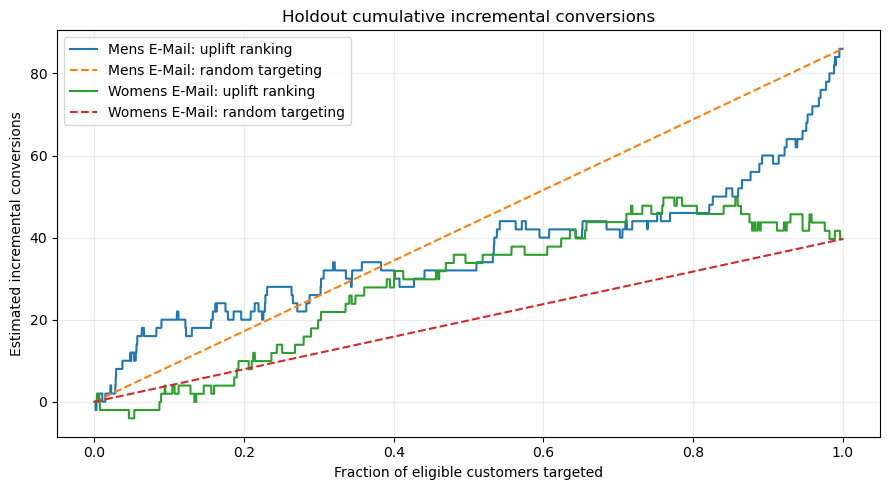


=== TARGETING POLICY RESULTS ===


,treatment,target_fraction_pct,customers_targeted,estimated_incremental_conversions,random_targeting_estimate,gain_vs_random_targeting
0,Mens E-Mail,10.0,1279,20.000,8.600,11.400
1,Mens E-Mail,20.0,2557,20.000,17.200,2.800
2,Mens E-Mail,30.0,3836,26.000,25.800,0.200
3,Mens E-Mail,50.0,6392,32.000,43.000,-11.000
4,Mens E-Mail,70.0,8949,42.000,60.200,-18.200
5,Mens E-Mail,100.0,12784,86.000,86.000,0.000
6,Womens E-Mail,10.0,1281,1.966,3.965,-1.999
7,Womens E-Mail,20.0,2562,9.921,7.930,1.992
8,Womens E-Mail,30.0,3843,19.880,11.894,7.986
9,Womens E-Mail,50.0,6404,33.816,19.824,13.993



=== QINI-STYLE SUMMARY ===


,treatment,eligible_customers,estimated_incremental_conversions_target_all,qini_style_area
0,Mens E-Mail,12784.0,86.000,-6.486
1,Womens E-Mail,12808.0,39.648,8.625


In [39]:
# ============================================================
# STAGE 5 — HOLDOUT UPLIFT EVALUATION
# Evaluation grain: one customer in the treatment/control pair
# ============================================================

import matplotlib.pyplot as plt
from math import ceil

TARGET_FRACTIONS = [0.10, 0.20, 0.30, 0.50, 0.70, 1.00]

policy_rows = []
qini_summary = {}

fig, ax = plt.subplots(figsize=(9, 5))

for treatment in TREATMENTS:

    # For this evaluation, retain only the relevant treatment arm
    # and No Email control arm. Exclude the other email treatment.
    eligible = test_df[
        test_df["segment"].isin([treatment, CONTROL])
    ].copy()

    # Align precomputed predictions to the matching holdout customers.
    scores = uplift_predictions[treatment].loc[
        eligible.index, "predicted_uplift"
    ]

    eligible["predicted_uplift"] = scores
    eligible["is_treatment"] = (
        eligible["segment"] == treatment
    ).astype(int)

    # Randomized assignment probability, conditional on this treatment/control pair.
    p_treatment = eligible["is_treatment"].mean()
    p_control = 1 - p_treatment

    # Inverse-probability-weighted incremental conversion contribution.
    eligible["incremental_contribution"] = np.where(
        eligible["is_treatment"] == 1,
        eligible["conversion"] / p_treatment,
        -eligible["conversion"] / p_control
    )

    # Sort customers from highest to lowest predicted uplift.
    eligible = eligible.sort_values(
        "predicted_uplift",
        ascending=False
    )

    n = len(eligible)
    cumulative_incremental = (
        eligible["incremental_contribution"].to_numpy().cumsum()
    )

    total_incremental = cumulative_incremental[-1]

    # Actual row-level prediction range, not cross-customer bounds.
    actual_scores = eligible["predicted_uplift"]

    print(f"\n=== {treatment} ===")
    print(f"Eligible holdout customers: {n:,}")
    print(
        "Actual predicted-uplift range:",
        f"{actual_scores.min():.4%} to {actual_scores.max():.4%}"
    )
    print(f"Estimated incremental conversions if targeting everyone: {total_incremental:.2f}")

    # Evaluate prespecified targeting fractions.
    for fraction in TARGET_FRACTIONS:
        k = ceil(fraction * n)

        model_incremental = cumulative_incremental[k - 1]
        random_targeting_incremental = fraction * total_incremental

        policy_rows.append({
            "treatment": treatment,
            "target_fraction_pct": fraction * 100,
            "customers_targeted": k,
            "estimated_incremental_conversions": model_incremental,
            "random_targeting_estimate": random_targeting_incremental,
            "gain_vs_random_targeting": (
                model_incremental - random_targeting_incremental
            )
        })

    # Qini-style cumulative-gain curve and area above random targeting.
    target_fraction = np.arange(1, n + 1) / n
    random_curve = target_fraction * total_incremental
    qini_curve = cumulative_incremental - random_curve

    x_curve = np.r_[0, target_fraction]
    incremental_curve = np.r_[0, cumulative_incremental]
    random_curve_plot = np.r_[0, random_curve]

    ax.plot(
        x_curve,
        incremental_curve,
        label=f"{treatment}: uplift ranking"
    )

    ax.plot(
        x_curve,
        random_curve_plot,
        linestyle="--",
        label=f"{treatment}: random targeting"
    )

    qini_area = np.trapz(qini_curve, target_fraction)

    qini_summary[treatment] = {
        "eligible_customers": n,
        "estimated_incremental_conversions_target_all": total_incremental,
        "qini_style_area": qini_area
    }

ax.set_title("Holdout cumulative incremental conversions")
ax.set_xlabel("Fraction of eligible customers targeted")
ax.set_ylabel("Estimated incremental conversions")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

policy_results = pd.DataFrame(policy_rows)
qini_results = pd.DataFrame(qini_summary).T.reset_index(
    names="treatment"
)

print("\n=== TARGETING POLICY RESULTS ===")
display(policy_results.round(3))

print("\n=== QINI-STYLE SUMMARY ===")
display(qini_results.round(3))

In [40]:
# ============================================================
# STAGE 6 — CAMPAIGN ECONOMICS
# All costs and margins below are explicit scenario assumptions.
# ============================================================

# Illustrative assumptions, in USD per recipient.
ASSUMED_EMAIL_COSTS = [0.01, 0.10, 0.25]
ASSUMED_MARGINS = [0.20, 0.30, 0.40]

economics_rows = []

for treatment in TREATMENTS:
    result = spend_results_df.loc[
        spend_results_df["treatment"] == treatment
    ].iloc[0]

    n_recipients = int(
        (df["segment"] == treatment).sum()
    )

    spend_lift = result["spend_lift_per_customer"]
    ci_low = result["bootstrap_ci_low"]
    ci_high = result["bootstrap_ci_high"]

    for margin in ASSUMED_MARGINS:
        break_even_cost = spend_lift * margin

        for email_cost in ASSUMED_EMAIL_COSTS:
            net_per_recipient = (
                spend_lift * margin - email_cost
            )

            economics_rows.append({
                "treatment": treatment,
                "margin_pct": margin * 100,
                "assumed_email_cost_usd": email_cost,
                "spend_lift_usd_per_customer": spend_lift,
                "break_even_email_cost_usd": break_even_cost,
                "net_contribution_usd_per_recipient": net_per_recipient,
                "estimated_incremental_profit_usd": (
                    net_per_recipient * n_recipients
                ),
                "profit_ci_low_usd": (
                    ci_low * margin - email_cost
                ) * n_recipients,
                "profit_ci_high_usd": (
                    ci_high * margin - email_cost
                ) * n_recipients
            })

economics_results = pd.DataFrame(economics_rows)

print("SCENARIOS ARE ILLUSTRATIVE, NOT OBSERVED BUSINESS INPUTS")

display(
    economics_results.round({
        "margin_pct": 1,
        "assumed_email_cost_usd": 3,
        "spend_lift_usd_per_customer": 4,
        "break_even_email_cost_usd": 4,
        "net_contribution_usd_per_recipient": 4,
        "estimated_incremental_profit_usd": 2,
        "profit_ci_low_usd": 2,
        "profit_ci_high_usd": 2
    })
)

SCENARIOS ARE ILLUSTRATIVE, NOT OBSERVED BUSINESS INPUTS


,treatment,margin_pct,assumed_email_cost_usd,spend_lift_usd_per_customer,break_even_email_cost_usd,net_contribution_usd_per_recipient,estimated_incremental_profit_usd,profit_ci_low_usd,profit_ci_high_usd
0,Mens E-Mail,20.0,0.01,0.7698,0.1540,0.1440,3067.47,1924.71,4305.29
1,Mens E-Mail,20.0,0.10,0.7698,0.1540,0.0540,1149.84,7.08,2387.66
2,Mens E-Mail,20.0,0.25,0.7698,0.1540,-0.0960,-2046.21,-3188.97,-808.39
3,Mens E-Mail,30.0,0.01,0.7698,0.2309,0.2209,4707.74,2993.60,6564.48
4,Mens E-Mail,30.0,0.10,0.7698,0.2309,0.1309,2790.11,1075.97,4646.85
5,Mens E-Mail,30.0,0.25,0.7698,0.2309,-0.0191,-405.94,-2120.08,1450.80
6,Mens E-Mail,40.0,0.01,0.7698,0.3079,0.2979,6348.01,4062.50,8823.66
7,Mens E-Mail,40.0,0.10,0.7698,0.3079,0.2079,4430.38,2144.87,6906.03
8,Mens E-Mail,40.0,0.25,0.7698,0.3079,0.0579,1234.33,-1051.18,3709.98
9,Womens E-Mail,20.0,0.01,0.4244,0.0849,0.0749,1601.51,545.46,2673.04


In [41]:
# ============================================================
# STAGE 7 — MASTER EXPERIMENT SCORECARD
# Grain: one row per treatment x outcome comparison
# ============================================================

holm_lookup = all_tests.set_index(
    ["treatment", "outcome"]
)["p_value_holm"]

scorecard_rows = []

for treatment in TREATMENTS:

    # Conversion
    r = conversion_results.loc[
        conversion_results["treatment"] == treatment
    ].iloc[0]

    scorecard_rows.append({
        "treatment": treatment,
        "outcome": "conversion",
        "treatment_rate_pct": r["treatment_rate"] * 100,
        "control_rate_pct": r["control_rate"] * 100,
        "lift": r["absolute_lift"] * 100,
        "lift_unit": "percentage points",
        "ci_low": r["ci_low"] * 100,
        "ci_high": r["ci_high"] * 100,
        "p_value_raw": r["p_value_raw"],
        "p_value_holm": holm_lookup.loc[(treatment, "conversion")]
    })

    # Visit
    r = visit_results.loc[
        visit_results["treatment"] == treatment
    ].iloc[0]

    scorecard_rows.append({
        "treatment": treatment,
        "outcome": "visit",
        "treatment_rate_pct": r["treatment_rate"] * 100,
        "control_rate_pct": r["control_rate"] * 100,
        "lift": r["absolute_lift"] * 100,
        "lift_unit": "percentage points",
        "ci_low": r["ci_low"] * 100,
        "ci_high": r["ci_high"] * 100,
        "p_value_raw": r["p_value_raw"],
        "p_value_holm": holm_lookup.loc[(treatment, "visit")]
    })

    # Spend
    r = spend_results_df.loc[
        spend_results_df["treatment"] == treatment
    ].iloc[0]

    scorecard_rows.append({
        "treatment": treatment,
        "outcome": "spend",
        "treatment_rate_pct": np.nan,
        "control_rate_pct": np.nan,
        "lift": r["spend_lift_per_customer"],
        "lift_unit": "spend units per customer",
        "ci_low": r["bootstrap_ci_low"],
        "ci_high": r["bootstrap_ci_high"],
        "p_value_raw": spend_test_results.loc[
            spend_test_results["treatment"] == treatment,
            "p_value_raw"
        ].iloc[0],
        "p_value_holm": holm_lookup.loc[(treatment, "spend")]
    })

master_scorecard = pd.DataFrame(scorecard_rows)

assert len(master_scorecard) == 6
assert master_scorecard["p_value_holm"].notna().all()

print("=== MASTER EXPERIMENT SCORECARD ===")
display(master_scorecard.round(6))

print("\n=== VALIDATION ===")
print("Expected comparisons: 6")
print(f"Actual comparisons: {len(master_scorecard)}")
print(
    "All comparisons have Holm-adjusted p-values:",
    master_scorecard["p_value_holm"].notna().all()
)

=== MASTER EXPERIMENT SCORECARD ===


,treatment,outcome,treatment_rate_pct,control_rate_pct,lift,lift_unit,ci_low,ci_high,p_value_raw,p_value_holm
0,Mens E-Mail,conversion,1.253109,0.572609,0.680501,percentage points,0.501434,0.864072,0.000000,0.000000
1,Mens E-Mail,visit,18.275684,10.616728,7.658956,percentage points,6.995331,8.322674,0.000000,0.000000
2,Mens E-Mail,spend,NaN,NaN,0.769827,spend units per customer,0.501662,1.060300,0.000200,0.000471
3,Womens E-Mail,conversion,0.883714,0.572609,0.311106,percentage points,0.150166,0.474547,0.000157,0.000471
4,Womens E-Mail,visit,15.140038,10.616728,4.523311,percentage points,3.889410,5.157434,0.000000,0.000000
5,Womens E-Mail,spend,NaN,NaN,0.424412,spend units per customer,0.177522,0.674923,0.001600,0.001600



=== VALIDATION ===
Expected comparisons: 6
Actual comparisons: 6
All comparisons have Holm-adjusted p-values: True


In [42]:
# ============================================================
# STAGE 5 — UPLIFT ROBUSTNESS
# Bootstrap policy gains and Qini-style area
# ============================================================

from math import ceil
from scipy.integrate import trapezoid

BOOTSTRAP_REPS = 500
TARGET_FRACTIONS = [0.10, 0.20, 0.30, 0.50, 0.70, 1.00]

robustness_rng = np.random.default_rng(20261011)


def evaluate_targeting_policy(
    treatment_scores,
    treatment_outcomes,
    control_scores,
    control_outcomes,
    target_fractions
):
    """Estimate incremental conversions under uplift-ranked targeting."""

    n_treatment = len(treatment_outcomes)
    n_control = len(control_outcomes)
    total_n = n_treatment + n_control

    p_treatment = n_treatment / total_n
    p_control = 1 - p_treatment

    scores = np.concatenate([treatment_scores, control_scores])

    is_treatment = np.concatenate([
        np.ones(n_treatment, dtype=int),
        np.zeros(n_control, dtype=int)
    ])

    outcomes = np.concatenate([
        treatment_outcomes,
        control_outcomes
    ])

    contributions = np.where(
        is_treatment == 1,
        outcomes / p_treatment,
        -outcomes / p_control
    )

    order = np.argsort(-scores, kind="mergesort")
    cumulative_incremental = np.cumsum(contributions[order])

    total_incremental = float(cumulative_incremental[-1])

    # Qini-style area above the random-targeting reference.
    fractions = np.arange(1, total_n + 1) / total_n
    qini_curve = cumulative_incremental - fractions * total_incremental

    qini_area = trapezoid(
        np.concatenate([[0.0], qini_curve]),
        x=np.concatenate([[0.0], fractions])
    )

    policy_metrics = {}

    for fraction in target_fractions:
        k = ceil(fraction * total_n)
        actual_fraction = k / total_n

        incremental = float(cumulative_incremental[k - 1])
        random_estimate = actual_fraction * total_incremental

        policy_metrics[fraction] = {
            "customers_targeted": k,
            "incremental_conversions": incremental,
            "random_targeting_estimate": random_estimate,
            "gain_vs_random": incremental - random_estimate
        }

    return policy_metrics, float(qini_area)


policy_point_rows = []
policy_bootstrap_rows = []
qini_robustness_rows = []

for treatment in TREATMENTS:

    eligible = test_df[
        test_df["segment"].isin([treatment, CONTROL])
    ].copy()

    eligible["predicted_uplift"] = uplift_predictions[treatment].loc[
        eligible.index, "predicted_uplift"
    ]

    treatment_rows = eligible[
        eligible["segment"] == treatment
    ]

    control_rows = eligible[
        eligible["segment"] == CONTROL
    ]

    t_scores = treatment_rows["predicted_uplift"].to_numpy()
    t_outcomes = treatment_rows["conversion"].to_numpy(dtype=float)

    c_scores = control_rows["predicted_uplift"].to_numpy()
    c_outcomes = control_rows["conversion"].to_numpy(dtype=float)

    # Point estimates on the original holdout.
    point_metrics, point_qini = evaluate_targeting_policy(
        t_scores,
        t_outcomes,
        c_scores,
        c_outcomes,
        TARGET_FRACTIONS
    )

    boot_policy_values = {
        fraction: np.empty(BOOTSTRAP_REPS)
        for fraction in TARGET_FRACTIONS
    }

    boot_policy_gains = {
        fraction: np.empty(BOOTSTRAP_REPS)
        for fraction in TARGET_FRACTIONS
    }

    boot_qini = np.empty(BOOTSTRAP_REPS)

    # Resample within randomized arms to preserve arm sample sizes.
    for b in range(BOOTSTRAP_REPS):

        t_idx = robustness_rng.integers(
            0, len(t_outcomes), size=len(t_outcomes)
        )

        c_idx = robustness_rng.integers(
            0, len(c_outcomes), size=len(c_outcomes)
        )

        boot_metrics, boot_area = evaluate_targeting_policy(
            t_scores[t_idx],
            t_outcomes[t_idx],
            c_scores[c_idx],
            c_outcomes[c_idx],
            TARGET_FRACTIONS
        )

        for fraction in TARGET_FRACTIONS:
            boot_policy_values[fraction][b] = (
                boot_metrics[fraction]["incremental_conversions"]
            )

            boot_policy_gains[fraction][b] = (
                boot_metrics[fraction]["gain_vs_random"]
            )

        boot_qini[b] = boot_area

    # Include the target-nobody baseline, whose incremental value is zero.
    policy_point_rows.append({
        "treatment": treatment,
        "target_fraction_pct": 0,
        "customers_targeted": 0,
        "estimated_incremental_conversions": 0.0,
        "random_targeting_estimate": 0.0,
        "gain_vs_random": 0.0
    })

    policy_bootstrap_rows.append({
        "treatment": treatment,
        "target_fraction_pct": 0,
        "incremental_ci_low": 0.0,
        "incremental_ci_high": 0.0,
        "gain_ci_low": 0.0,
        "gain_ci_high": 0.0
    })

    for fraction in TARGET_FRACTIONS:
        point = point_metrics[fraction]

        policy_point_rows.append({
            "treatment": treatment,
            "target_fraction_pct": fraction * 100,
            "customers_targeted": point["customers_targeted"],
            "estimated_incremental_conversions": (
                point["incremental_conversions"]
            ),
            "random_targeting_estimate": (
                point["random_targeting_estimate"]
            ),
            "gain_vs_random": point["gain_vs_random"]
        })

        incremental_ci = np.quantile(
            boot_policy_values[fraction],
            [0.025, 0.975]
        )

        gain_ci = np.quantile(
            boot_policy_gains[fraction],
            [0.025, 0.975]
        )

        policy_bootstrap_rows.append({
            "treatment": treatment,
            "target_fraction_pct": fraction * 100,
            "incremental_ci_low": incremental_ci[0],
            "incremental_ci_high": incremental_ci[1],
            "gain_ci_low": gain_ci[0],
            "gain_ci_high": gain_ci[1]
        })

    qini_ci = np.quantile(boot_qini, [0.025, 0.975])

    qini_robustness_rows.append({
        "treatment": treatment,
        "qini_style_area": point_qini,
        "qini_ci_low": qini_ci[0],
        "qini_ci_high": qini_ci[1],
        "bootstrap_reps": BOOTSTRAP_REPS
    })


policy_point_df = pd.DataFrame(policy_point_rows)
policy_ci_df = pd.DataFrame(policy_bootstrap_rows)

policy_robustness = policy_point_df.merge(
    policy_ci_df,
    on=["treatment", "target_fraction_pct"],
    validate="one_to_one"
)

qini_robustness = pd.DataFrame(qini_robustness_rows)

print("=== POLICY GAINS WITH BOOTSTRAP UNCERTAINTY ===")
display(policy_robustness.round(3))

print("\n=== QINI-STYLE AREA WITH BOOTSTRAP UNCERTAINTY ===")
display(qini_robustness.round(3))

=== POLICY GAINS WITH BOOTSTRAP UNCERTAINTY ===


,treatment,target_fraction_pct,customers_targeted,estimated_incremental_conversions,random_targeting_estimate,gain_vs_random,incremental_ci_low,incremental_ci_high,gain_ci_low,gain_ci_high
0,Mens E-Mail,0.0,0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,Mens E-Mail,10.0,1279,20.000,8.604,11.396,2.000,39.050,-4.605,28.596
2,Mens E-Mail,20.0,2557,20.000,17.201,2.799,-3.050,45.050,-18.631,23.998
3,Mens E-Mail,30.0,3836,26.000,25.805,0.195,0.000,56.000,-20.805,26.006
4,Mens E-Mail,50.0,6392,32.000,43.000,-11.000,0.950,66.000,-33.000,11.000
5,Mens E-Mail,70.0,8949,42.000,60.201,-18.201,8.000,80.000,-38.622,2.704
6,Mens E-Mail,100.0,12784,86.000,86.000,0.000,46.950,132.000,0.000,0.000
7,Womens E-Mail,0.0,0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
8,Womens E-Mail,10.0,1281,1.966,3.965,-1.999,-9.089,15.948,-12.604,10.781
9,Womens E-Mail,20.0,2562,9.921,7.931,1.991,-6.090,25.925,-12.223,16.788



=== QINI-STYLE AREA WITH BOOTSTRAP UNCERTAINTY ===


,treatment,qini_style_area,qini_ci_low,qini_ci_high,bootstrap_reps
0,Mens E-Mail,-6.485,-22.057,8.546,500
1,Womens E-Mail,8.626,-4.029,20.226,500


In [43]:
# ============================================================
# UPLIFT ROBUSTNESS CHECK 2
# Compare model ranking across different random splits
# ============================================================

SPLIT_SEEDS = [17, 42, 2026]
FRACTIONS = [0.10, 0.30, 0.50, 0.70]

split_results = []

strata = (
    df["segment"].astype(str)
    + " | "
    + df["conversion"].astype(str)
)

for seed in SPLIT_SEEDS:

    train_idx, test_idx = train_test_split(
        df.index,
        test_size=0.30,
        random_state=seed,
        stratify=strata
    )

    train = df.loc[train_idx]
    test = df.loc[test_idx]
    X_test = test[FEATURES]

    print(f"\nSplit seed: {seed}")

    for treatment in TREATMENTS:

        train_pair = train[
            train["segment"].isin([treatment, CONTROL])
        ]

        is_treatment = train_pair["segment"] == treatment

        model_t = make_conversion_model()
        model_c = make_conversion_model()

        model_t.fit(
            train_pair.loc[is_treatment, FEATURES],
            train_pair.loc[is_treatment, TARGET]
        )

        model_c.fit(
            train_pair.loc[~is_treatment, FEATURES],
            train_pair.loc[~is_treatment, TARGET]
        )

        p_t = model_t.predict_proba(X_test)[:, 1]
        p_c = model_c.predict_proba(X_test)[:, 1]

        scored = test.copy()
        scored["predicted_uplift"] = p_t - p_c

        eligible = scored[
            scored["segment"].isin([treatment, CONTROL])
        ]

        t_rows = eligible[eligible["segment"] == treatment]
        c_rows = eligible[eligible["segment"] == CONTROL]

        policy_metrics, qini_area = evaluate_targeting_policy(
            t_rows["predicted_uplift"].to_numpy(),
            t_rows[TARGET].to_numpy(dtype=float),
            c_rows["predicted_uplift"].to_numpy(),
            c_rows[TARGET].to_numpy(dtype=float),
            FRACTIONS
        )

        row = {
            "seed": seed,
            "treatment": treatment,
            "holdout_customers": len(eligible),
            "qini_style_area": qini_area
        }

        for fraction in FRACTIONS:
            row[f"gain_top_{int(fraction * 100)}_pct"] = (
                policy_metrics[fraction]["gain_vs_random"]
            )

        split_results.append(row)

qini_stability = (
    split_stability_df
    .groupby("treatment")
    .agg(
        splits=("qini_style_area", "size"),
        positive_qini_splits=(
            "qini_style_area",
            lambda s: int((s > 0).sum())
        ),
        negative_qini_splits=(
            "qini_style_area",
            lambda s: int((s < 0).sum())
        ),
        mean_qini_area=("qini_style_area", "mean"),
        std_qini_area=("qini_style_area", "std")
    )
    .round(3)
)

display(qini_stability)


Split seed: 17

Split seed: 42

Split seed: 2026


NameError: name 'split_stability_df' is not defined

In [ ]:
# ============================================================
# STAGE 5 — SIMPLE BUSINESS BASELINE VS UPLIFT MODEL
# Ranking baseline: highest historical spend first
# Evaluation: same randomized holdout and policy metric
# ============================================================

FRACTIONS = [0.10, 0.20, 0.30, 0.50, 0.70, 1.00]

baseline_policy_rows = []
baseline_qini_rows = []

for treatment in TREATMENTS:

    eligible = test_df[
        test_df["segment"].isin([treatment, CONTROL])
    ].copy()

    t_rows = eligible[
        eligible["segment"] == treatment
    ].copy()

    c_rows = eligible[
        eligible["segment"] == CONTROL
    ].copy()

    # Model ranking: use previously generated uplift predictions.
    model_t_scores = uplift_predictions[treatment].loc[
        t_rows.index, "predicted_uplift"
    ].to_numpy()

    model_c_scores = uplift_predictions[treatment].loc[
        c_rows.index, "predicted_uplift"
    ].to_numpy()

    model_metrics, model_qini = evaluate_targeting_policy(
        model_t_scores,
        t_rows[TARGET].to_numpy(dtype=float),
        model_c_scores,
        c_rows[TARGET].to_numpy(dtype=float),
        FRACTIONS
    )

    # Simple business ranking: target customers with greater
    # historical spend first. This is a benchmark, not an uplift model.
    history_metrics, history_qini = evaluate_targeting_policy(
        t_rows["history"].to_numpy(dtype=float),
        t_rows[TARGET].to_numpy(dtype=float),
        c_rows["history"].to_numpy(dtype=float),
        c_rows[TARGET].to_numpy(dtype=float),
        FRACTIONS
    )

    for policy_name, metrics in [
        ("T-learner uplift", model_metrics),
        ("Historical spend baseline", history_metrics)
    ]:
        for fraction in FRACTIONS:
            result = metrics[fraction]

            baseline_policy_rows.append({
                "treatment": treatment,
                "policy": policy_name,
                "target_fraction_pct": fraction * 100,
                "customers_targeted": result["customers_targeted"],
                "estimated_incremental_conversions": (
                    result["incremental_conversions"]
                ),
                "gain_vs_random": result["gain_vs_random"]
            })

    baseline_qini_rows.extend([
        {
            "treatment": treatment,
            "policy": "T-learner uplift",
            "qini_style_area": model_qini
        },
        {
            "treatment": treatment,
            "policy": "Historical spend baseline",
            "qini_style_area": history_qini
        }
    ])

baseline_policy_df = pd.DataFrame(baseline_policy_rows)
baseline_qini_df = pd.DataFrame(baseline_qini_rows)

print("=== TARGETING POLICY COMPARISON ===")
display(baseline_policy_df.round(3))

print("\n=== QINI-STYLE AREA COMPARISON ===")
display(baseline_qini_df.round(3))

In [44]:
import pandas as pd
import numpy as np
df = pd.read_csv("data/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv")

print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print(df["segment"].value_counts())

Rows: 64000
Columns: ['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend']
segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64


In [45]:
from statsmodels.stats.proportion import confint_proportions_2indep

control = df[df["segment"] == "No E-Mail"]["conversion"]

results = []

for campaign in ["Mens E-Mail", "Womens E-Mail"]:
    treatment = df[df["segment"] == campaign]["conversion"]

    p_t = treatment.mean()
    p_c = control.mean()

    # Difference in conversion rates, expressed in percentage points
    lift_pp = (p_t - p_c) * 100

    # 95% confidence interval for the difference in proportions
    ci_low, ci_high = confint_proportions_2indep(
        int(treatment.sum()),
        len(treatment),
        int(control.sum()),
        len(control),
        method="newcomb",
        compare="diff",
        alpha=0.05
    )

    results.append({
        "Campaign": campaign,
        "Treatment customers": len(treatment),
        "Treatment conversions": int(treatment.sum()),
        "Treatment conversion rate (%)": p_t * 100,
        "Control customers": len(control),
        "Control conversions": int(control.sum()),
        "Control conversion rate (%)": p_c * 100,
        "Conversion lift (pp)": lift_pp,
        "95% CI lower (pp)": ci_low * 100,
        "95% CI upper (pp)": ci_high * 100
    })

ci_results = pd.DataFrame(results)
ci_results.round(4)

,Campaign,Treatment customers,Treatment conversions,Treatment conversion rate (%),Control customers,Control conversions,Control conversion rate (%),Conversion lift (pp),95% CI lower (pp),95% CI upper (pp)
0,Mens E-Mail,21307,267,1.2531,21306,122,0.5726,0.6805,0.5014,0.8641
1,Womens E-Mail,21387,189,0.8837,21306,122,0.5726,0.3111,0.1502,0.4745


In [46]:
ci_results.to_csv(
    "conversion_lift_confidence_intervals.csv",
    index=False
)

print("Exported successfully.")

Exported successfully.


In [47]:
from statsmodels.stats.proportion import confint_proportions_2indep

control = df[df["segment"] == "No E-Mail"]["visit"]

visit_results = []

for campaign in ["Mens E-Mail", "Womens E-Mail"]:
    treatment = df[df["segment"] == campaign]["visit"]

    lift_pp = (treatment.mean() - control.mean()) * 100

    ci_low, ci_high = confint_proportions_2indep(
        int(treatment.sum()),
        len(treatment),
        int(control.sum()),
        len(control),
        method="newcomb",
        compare="diff",
        alpha=0.05
    )

    visit_results.append({
        "Campaign": campaign,
        "Visit lift (pp)": lift_pp,
        "95% CI lower (pp)": ci_low * 100,
        "95% CI upper (pp)": ci_high * 100
    })

visit_ci_results = pd.DataFrame(visit_results)
visit_ci_results.round(4)

,Campaign,Visit lift (pp),95% CI lower (pp),95% CI upper (pp)
0,Mens E-Mail,7.6590,6.9953,8.3227
1,Womens E-Mail,4.5233,3.8894,5.1574


In [48]:
visit_ci_results.to_csv("visit_lift_confidence_intervals.csv", index=False)

In [50]:

# Spend Lift: bootstrap 95% confidence intervals

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n_boot = 10_000
chunk_size = 100

control = df.loc[df["segment"] == "No E-Mail", "spend"].to_numpy()

assert len(control) == 21306, "Unexpected control group size"
assert not np.isnan(control).any(), "Control spend contains missing values"

def bootstrap_spend_lift(treatment, control, n_boot=10_000):
    if np.isnan(treatment).any() or np.isnan(control).any():
        raise ValueError("Spend contains missing values; investigate before proceeding.")

    observed_lift = treatment.mean() - control.mean()
    bootstrap_lifts = []

    for start in range(0, n_boot, chunk_size):
        size = min(chunk_size, n_boot - start)

        treatment_samples = rng.choice(
            treatment, size=(size, len(treatment)), replace=True
        )
        control_samples = rng.choice(
            control, size=(size, len(control)), replace=True
        )

        differences = treatment_samples.mean(axis=1) - control_samples.mean(axis=1)
        bootstrap_lifts.extend(differences)

    lower, upper = np.percentile(bootstrap_lifts, [2.5, 97.5])

    return observed_lift, lower, upper

spend_results = []

for campaign in ["Mens E-Mail", "Womens E-Mail"]:
    treatment = df.loc[df["segment"] == campaign, "spend"].to_numpy()

    lift, lower, upper = bootstrap_spend_lift(treatment, control)

    spend_results.append({
        "Campaign": campaign,
        "Spend lift ($)": lift,
        "95% CI lower ($)": lower,
        "95% CI upper ($)": upper
    })

spend_ci_results = pd.DataFrame(spend_results)
spend_ci_results.round(4)


,Campaign,Spend lift ($),95% CI lower ($),95% CI upper ($)
0,Mens E-Mail,0.7698,0.4823,1.0545
1,Womens E-Mail,0.4244,0.1716,0.6878


In [51]:
spend_ci_results.to_csv(
    "spend_lift_confidence_intervals.csv",
    index=False
)

print("Exported successfully.")

Exported successfully.
